### SEMMA · Fase 5: Assess

Evaluación del modelo final con el grupo de prueba.

- **Entradas:** `semma/data/interim/test_clean.csv`, `semma/models/logistic_regression.joblib`, `semma/models/baseline.joblib`, `semma/data/processed/cv_results.csv`
- **Salidas:**
  - `semma/data/processed/metrics.csv`: métricas globales
  - `semma/data/processed/class_report.csv`: métricas por especie
  - `semma/data/processed/misclassified.csv`: registros mal clasificados
  - `semma/figures/assess_confusion_matrix.png`: matriz de confusión

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Carga de datos y modelos

In [3]:
test = pd.read_csv(INTERIM_DIR / "test_clean.csv")

TARGET = "species"
FEATURES = [
    "culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g",
    "island", "sex",
]

X_test = test[FEATURES]
y_test = test[TARGET]

models = {
    "baseline_most_frequent": joblib.load(MODELS_DIR / "baseline.joblib"),
    "logistic_regression": joblib.load(MODELS_DIR / "logistic_regression.joblib"),
}

print(f"Registros de prueba: {len(X_test)}")
print(y_test.value_counts().to_string())

Registros de prueba: 69
species
Adelie       30
Gentoo       25
Chinstrap    14


#### Predicciones

In [4]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

#### Métricas globales

In [5]:
metrics = pd.DataFrame([
    {
        "modelo": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "errores": int((y_pred != y_test).sum()),
        "n": len(y_test),
    }
    for name, y_pred in predictions.items()
]).round(4)
metrics

,modelo,accuracy,balanced_accuracy,f1_macro,errores,n
0,baseline_most_frequent,0.4348,0.3333,0.2020,39,69
1,logistic_regression,0.9855,0.9889,0.9829,1,69


#### Validación cruzada frente a prueba

In [6]:
cv_results = pd.read_csv(PROCESSED_DIR / "cv_results.csv")
best_c = models["logistic_regression"].named_steps["classifier"].C

cv_lr = cv_results[(cv_results["modelo"] == "logistic_regression") & (cv_results["C"] == best_c)]
cv_base = cv_results[cv_results["modelo"] == "baseline_most_frequent"]

pd.DataFrame({
    "f1_macro_cv": [cv_base["f1_macro_mean"].iloc[0], cv_lr["f1_macro_mean"].iloc[0]],
    "f1_macro_test": metrics["f1_macro"].values,
}, index=metrics["modelo"]).round(4)

,f1_macro_cv,f1_macro_test
modelo,,
baseline_most_frequent,0.2047,0.2020
logistic_regression,1.0000,0.9829


#### Métricas por especie

In [7]:
y_pred = predictions["logistic_regression"]

class_report = pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True, zero_division=0)
).T.drop(index="accuracy").round(4)
class_report["support"] = class_report["support"].astype(int)
class_report

,precision,recall,f1-score,support
Adelie,1.0000,0.9667,0.9831,30
Chinstrap,0.9333,1.0000,0.9655,14
Gentoo,1.0000,1.0000,1.0000,25
macro avg,0.9778,0.9889,0.9829,69
weighted avg,0.9865,0.9855,0.9856,69


#### Matriz de confusión

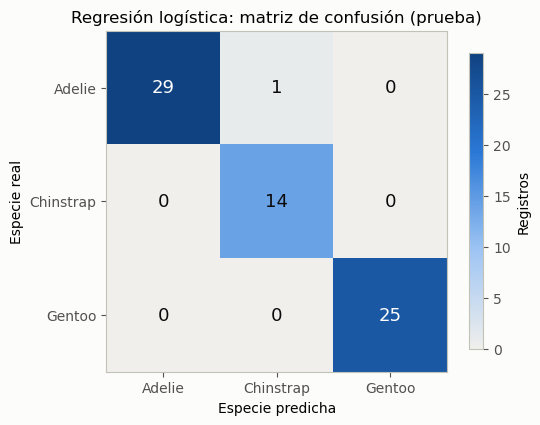

In [8]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
cm = confusion_matrix(y_test, y_pred, labels=SPECIES)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap=cmap)
for i in range(len(SPECIES)):
    for j in range(len(SPECIES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="#ffffff" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks(range(len(SPECIES)), SPECIES)
ax.set_yticks(range(len(SPECIES)), SPECIES)
ax.set_xlabel("Especie predicha")
ax.set_ylabel("Especie real")
ax.set_title("Regresión logística: matriz de confusión (prueba)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Registros")
fig.savefig(FIGURES_DIR / "assess_confusion_matrix.png")
plt.show()

#### Registros mal clasificados

In [9]:
model = models["logistic_regression"]
proba = pd.DataFrame(
    model.predict_proba(X_test),
    columns=[f"prob_{c}" for c in model.classes_],
    index=test.index,
).round(3)

results = pd.concat([test, proba], axis=1)
results["predicted"] = y_pred

misclassified = results[results["predicted"] != results[TARGET]]
print(f"Registros mal clasificados: {len(misclassified)} de {len(results)}")
misclassified

Registros mal clasificados: 1 de 69


,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,prob_Adelie,prob_Chinstrap,prob_Gentoo,predicted
28,37,Adelie,Dream,42.2,18.5,180.0,3550.0,FEMALE,0.431,0.569,0.0,Chinstrap


#### Confianza de las predicciones

Probabilidad máxima asignada en cada predicción.

In [10]:
results["max_prob"] = proba.max(axis=1)
results["correcto"] = results["predicted"] == results[TARGET]

bins = [0, 0.6, 0.8, 0.95, 1.0]
labels = ["< 0.60", "0.60–0.80", "0.80–0.95", "≥ 0.95"]
pd.crosstab(
    pd.cut(results["max_prob"], bins=bins, labels=labels, include_lowest=True),
    results["correcto"].map({True: "correcta", False: "incorrecta"}),
    dropna=False,
).rename_axis(index="probabilidad máxima", columns="predicción")

predicción,correcta,incorrecta
probabilidad máxima,,
< 0.60,1,1
0.60–0.80,0,0
0.80–0.95,1,0
≥ 0.95,66,0


#### Guardado de resultados

In [11]:
metrics.to_csv(PROCESSED_DIR / "metrics.csv", index=False)
class_report.to_csv(PROCESSED_DIR / "class_report.csv")
misclassified.to_csv(PROCESSED_DIR / "misclassified.csv", index=False)

for path in [
    PROCESSED_DIR / "metrics.csv",
    PROCESSED_DIR / "class_report.csv",
    PROCESSED_DIR / "misclassified.csv",
    FIGURES_DIR / "assess_confusion_matrix.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\metrics.csv
Guardado: ..\data\processed\class_report.csv
Guardado: ..\data\processed\misclassified.csv
Guardado: ..\figures\assess_confusion_matrix.png
